In [1]:
# "nbsphinx": "hidden"
import os

os.chdir("../../../tests/datasets")

# Projected maps

A `Galaxy` is, at heart, a long table: one row per particle. Projected maps are another *view* of the same data, where the unit of analysis is no longer the particle but the **pixel** of an image, as an integral field spectrograph (IFU) would see the galaxy.

Every pixel condenses all the particles that fall on it, along the whole line of sight, into a few quantities:

| Column | Meaning | Unit |
|---|---|---|
| `n_particles` | number of particles in the pixel | |
| `mass` | total mass in the pixel | M$_\odot$ |
| `surface_density` | mass over the pixel area | M$_\odot$ kpc$^{-2}$ |
| `v_los` | mass weighted mean line of sight velocity | km s$^{-1}$ |
| `sigma_los` | mass weighted line of sight velocity dispersion | km s$^{-1}$ |

## Preparing the galaxy

The maps are centered on the origin and the projections assume the stellar angular momentum points along $z$, so the galaxy must be centered and aligned first. By default `star_align()` uses the stars within 30 kpc to compute the rotation.

In [2]:
import matplotlib.pyplot as plt

import galaxychop as gchop

gal = gchop.read_hdf5("gal394242.h5")
gal = gchop.preproc.star_align(gchop.preproc.center(gal))
gal

,Particles,$\mathrm{M_{\odot}}$
Stars ⭐,37393,3.74e+10
Dark Matter ⚫​,155101,1.16e+12
Gas 💨,80153,1.22e+11


## The maps as data

`Galaxy.projected_maps()` returns a `DataFrame` with one row per pixel. Two projections are available:

- `"edge-on"` (the default): the image is the $x$-$z$ plane and the line of sight velocity is $v_y$.
- `"face-on"`: the image is the $x$-$y$ plane and the line of sight velocity is $v_z$.

By default only the stars are projected.

In [3]:
maps = gal.projected_maps(projection="edge-on", bins=100, half_width=20)
maps

,x,z,n_particles,mass,surface_density,v_los,sigma_los
0,-19.8,-19.8,0,0.0,0.0,NaN,NaN
1,-19.4,-19.8,0,0.0,0.0,NaN,NaN
2,-19.0,-19.8,0,0.0,0.0,NaN,NaN
3,-18.6,-19.8,0,0.0,0.0,NaN,NaN
4,-18.2,-19.8,0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...
9995,18.2,19.8,0,0.0,0.0,NaN,NaN
9996,18.6,19.8,0,0.0,0.0,NaN,NaN
9997,19.0,19.8,0,0.0,0.0,NaN,NaN
9998,19.4,19.8,0,0.0,0.0,NaN,NaN


The grid is always complete: empty pixels are kept (with zero mass and `NaN` velocities), so for the same `bins` every galaxy yields a table of the same shape. The grid geometry travels with the table in its `attrs`:

In [4]:
maps.attrs

{'projection': 'edge-on',
 'bins': 100,
 'half_width': 20.0,
 'pixel_size': 0.4,
 'min_particles': 1,
 'components': None}

Pivoting any column gives the image as a 2D table:

In [5]:
maps.pivot(index="z", columns="x", values="surface_density").head()

x,-19.8,-19.4,-19.0,-18.6,-18.2,-17.8,-17.4,-17.0,-16.6,-16.2,...,16.2,16.6,17.0,17.4,17.8,18.2,18.6,19.0,19.4,19.8
z,,,,,,,,,,,,,,,,,,,,,
-19.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,7.349333e+06,0.0,0.0,0.0,0.000000e+00,0.0
-19.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0
-19.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0
-18.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0
-18.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,6.173877e+06,0.0


## Plotting the maps

`galaxy.plot.projected_map()` draws any of the quantities. Densities are drawn on a logarithmic scale and empty pixels are left blank.

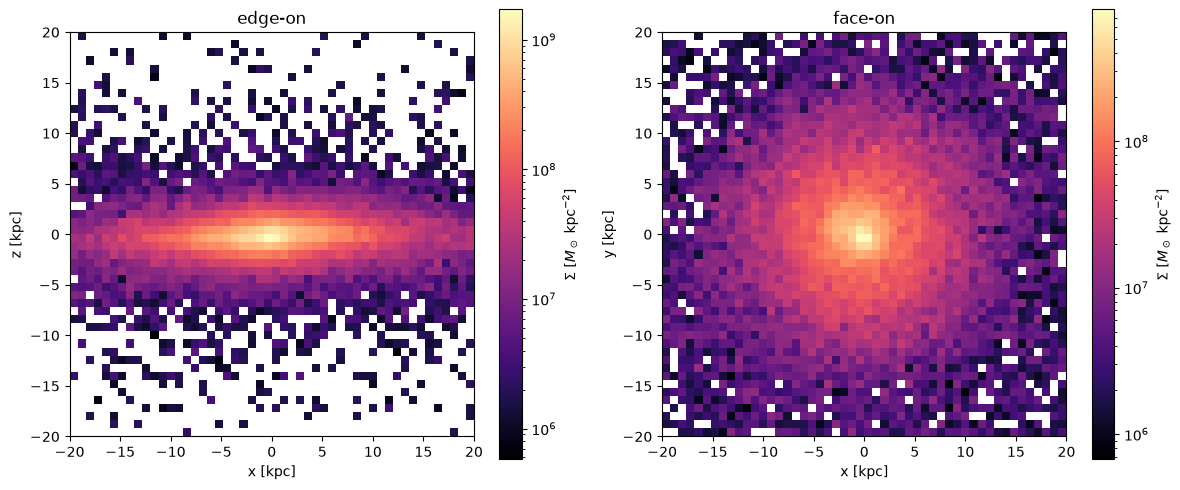

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

gal.plot.projected_map(projection="edge-on", half_width=20, ax=axes[0])
gal.plot.projected_map(projection="face-on", half_width=20, ax=axes[1])

fig.tight_layout()

### Kinematics

Pixels with only a handful of particles give noisy velocities (a lone particle has zero dispersion!). `min_particles` blanks out the kinematics of those pixels, much like a signal-to-noise cut on observed maps. `v_los` uses a diverging colormap centered on zero, so the approaching and receding sides of the disk are easy to tell apart.

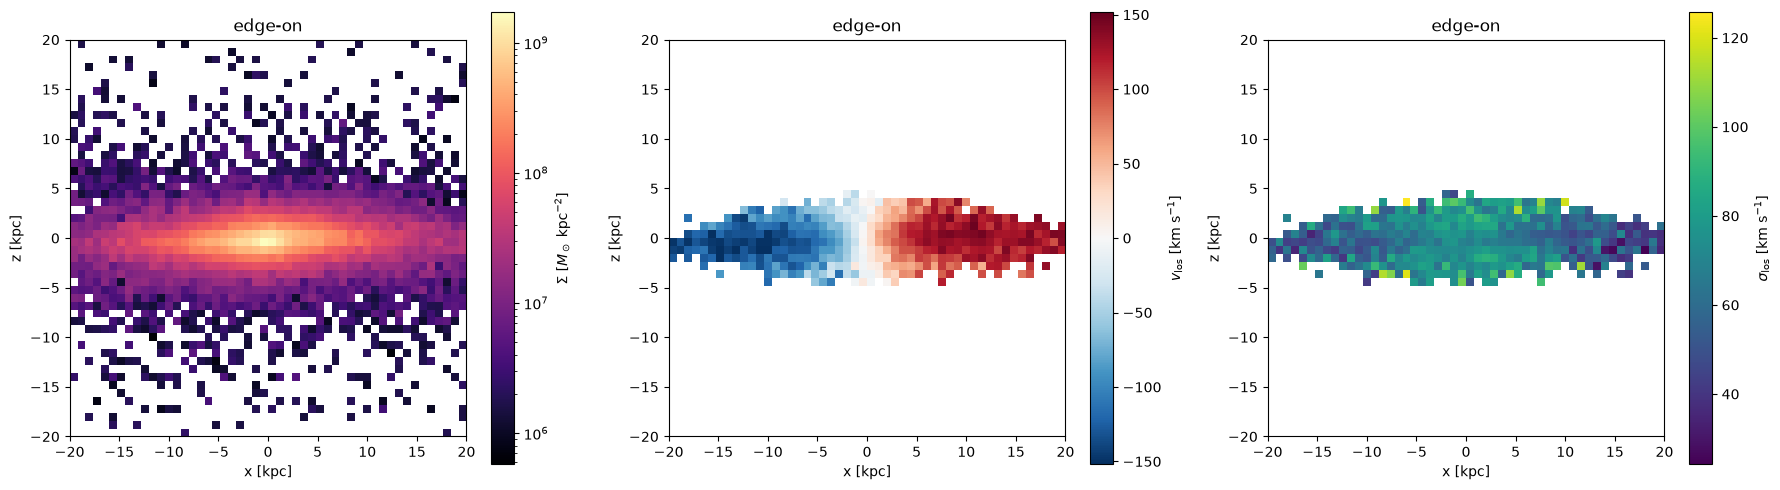

In [7]:
kws = dict(projection="edge-on", half_width=20, min_particles=10)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

gal.plot.projected_map("surface_density", ax=axes[0], **kws)
gal.plot.projected_map("v_los", ax=axes[1], **kws)
gal.plot.projected_map("sigma_los", ax=axes[2], **kws)

fig.tight_layout()

Seen face-on, the rotation is in the plane of the sky, so the line of sight velocity is close to zero everywhere and the dispersion shows the vertical motions of the stars.

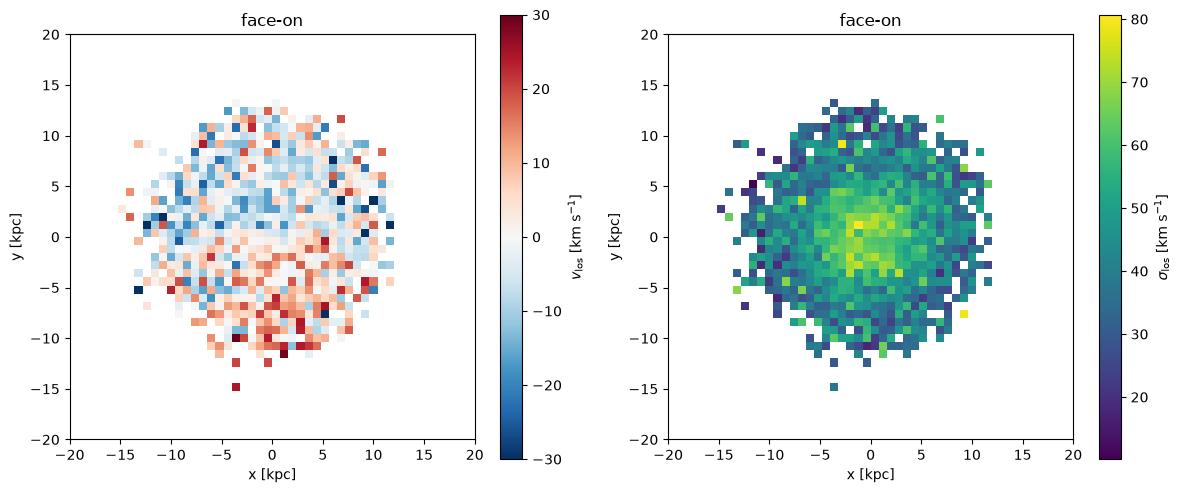

In [8]:
kws = dict(projection="face-on", half_width=20, min_particles=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

gal.plot.projected_map("v_los", ax=axes[0], **kws)
gal.plot.projected_map("sigma_los", ax=axes[1], **kws)

fig.tight_layout()

### Other particle types

`ptypes` selects which particle types are projected; several of them are pooled together. Every `matplotlib` `pcolormesh` argument (`cmap`, `vmin`, `vmax`, `norm`, ...) can be passed too.

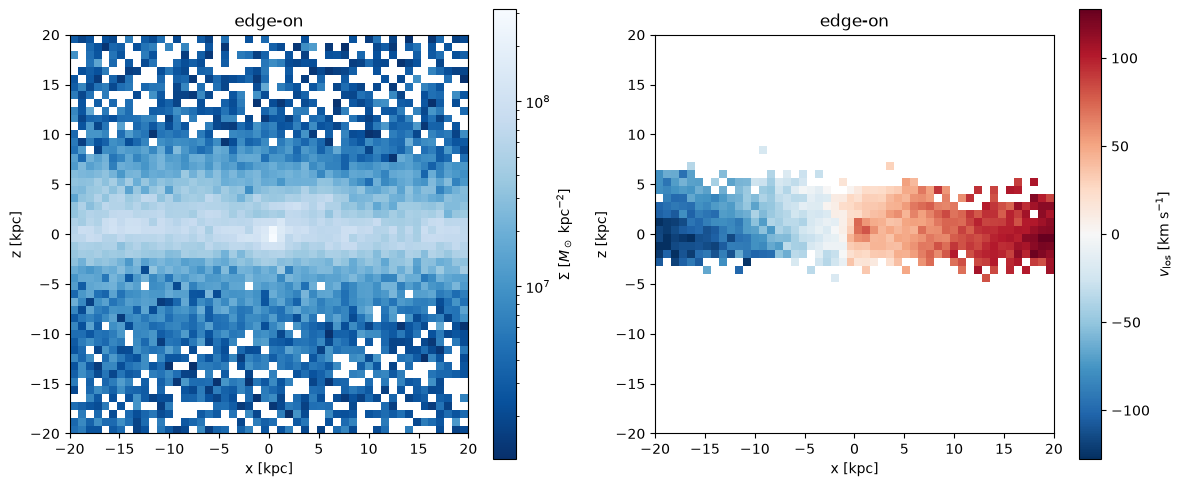

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

gal.plot.projected_map(
    ptypes=("gas",), half_width=20, cmap="Blues_r", ax=axes[0]
)
gal.plot.projected_map(
    "v_los", ptypes=("gas",), half_width=20, min_particles=10, ax=axes[1]
)

fig.tight_layout()

## Maps of the components

A `DecomposedGalaxy` adds the `components` parameter, which keeps only the particles of some components. Here the galaxy is split into a disk and a spheroid using a threshold on the circularity.

In [10]:
dgal = gchop.decomposers.JThreshold().decompose(gal)
dgal

<DecomposedGalaxy method='JThreshold', dark_matter=155101, gas=80153, probabilities=False, components=['Disk', 'Spheroid', 'dark_matter', 'gas', 'stars']>

In [11]:
dgal.projected_maps(components="Disk", bins=50)

,x,z,n_particles,mass,surface_density,v_los,sigma_los
0,-48.395152,-48.395152,0,0.0,0.0,NaN,NaN
1,-46.419840,-48.395152,0,0.0,0.0,NaN,NaN
2,-44.444527,-48.395152,0,0.0,0.0,NaN,NaN
3,-42.469215,-48.395152,0,0.0,0.0,NaN,NaN
4,-40.493903,-48.395152,0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...
2495,40.493903,48.395152,0,0.0,0.0,NaN,NaN
2496,42.469215,48.395152,0,0.0,0.0,NaN,NaN
2497,44.444527,48.395152,0,0.0,0.0,NaN,NaN
2498,46.419840,48.395152,0,0.0,0.0,NaN,NaN


When `half_width` is not given, it is computed from all the particles of `ptypes`, not only from the selected components. So the maps of every component share the same grid: they can be compared pixel by pixel, and their masses add up to the map of the whole galaxy.

To compare them visually it is also convenient to share the color scale, passing the same `vmin`/`vmax` to every map.

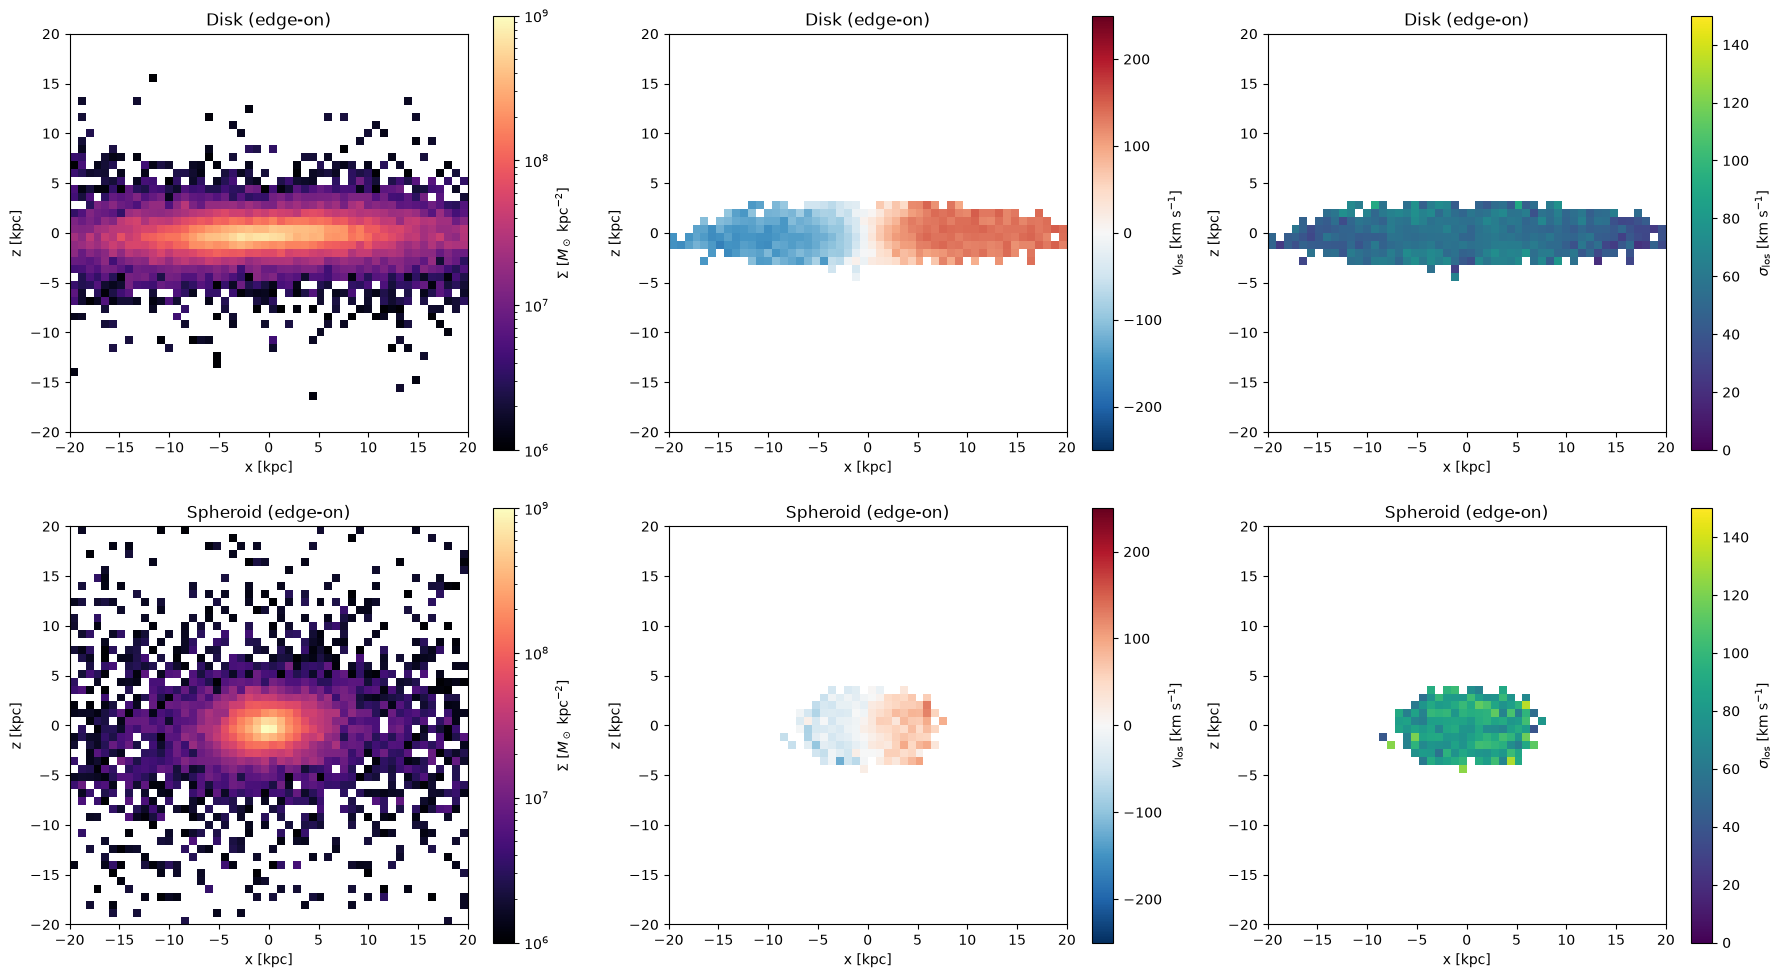

In [12]:
from matplotlib.colors import LogNorm

components = ["Disk", "Spheroid"]
scales = {
    "surface_density": dict(norm=LogNorm(vmin=1e6, vmax=1e9)),
    "v_los": dict(vmin=-250, vmax=250),
    "sigma_los": dict(vmin=0, vmax=150),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for row, component in zip(axes, components):
    for ax, (quantity, scale) in zip(row, scales.items()):
        dgal.plot.projected_map(
            quantity,
            components=component,
            half_width=20,
            min_particles=10,
            ax=ax,
            **scale,
        )

fig.tight_layout()

The disk is thin and rotates fast with a low dispersion, while the spheroid is round, rotates much more slowly and is dynamically hot.

Several components can also be pooled into a single map:

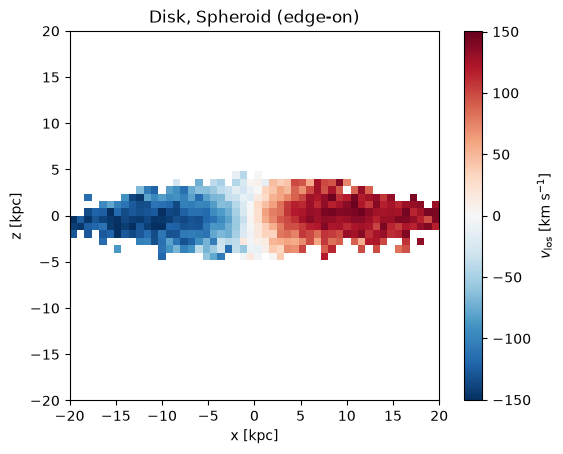

In [13]:
dgal.plot.projected_map(
    "v_los",
    components=("Disk", "Spheroid"),
    half_width=20,
    min_particles=10,
);